In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test, pairwise_logrank_test, proportional_hazard_test
from lifelines.plotting import add_at_risk_counts
import statsmodels.formula.api as smf

PROC = Path("../data/processed")
FIG  = Path("../results/figures"); TAB = Path("../results/tables")
SUB_ORDER = ["LumA", "LumB", "Her2", "Basal", "Normal"]
PALETTE   = dict(zip(SUB_ORDER, ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]))
STAGES    = ["Stage I", "Stage II", "Stage III", "Stage IV"]
sns.set_theme(style="whitegrid", font_scale=1.05)

meta   = pd.read_csv(PROC / "meta_clean.csv")
logcpm = pd.read_csv(PROC / "logcpm.csv", index_col="gene")
assert (logcpm.columns == meta["sample_id"]).all()

# proliferation score = mean z-score of the 11 PAM50 proliferation genes (Nielsen et al., 2010)
PROLIF = ["BIRC5", "CCNB1", "CDC20", "NUF2", "CEP55", "NDC80", "MKI67", "PTTG1", "RRM2", "TYMS", "UBE2C"]
z = logcpm.loc[PROLIF].T
meta["prolif_score"] = ((z - z.mean()) / z.std()).mean(axis=1).values

surv = meta.dropna(subset=["OS_months", "OS_event"]).copy()
surv = surv[surv["OS_months"] > 0]
print(f"Survival analysis: {len(surv)} patients, {int(surv['OS_event'].sum())} deaths, "
      f"median follow-up {surv['OS_months'].median():.1f} months")

Survival analysis: 1056 patients, 150 deaths, median follow-up 27.9 months


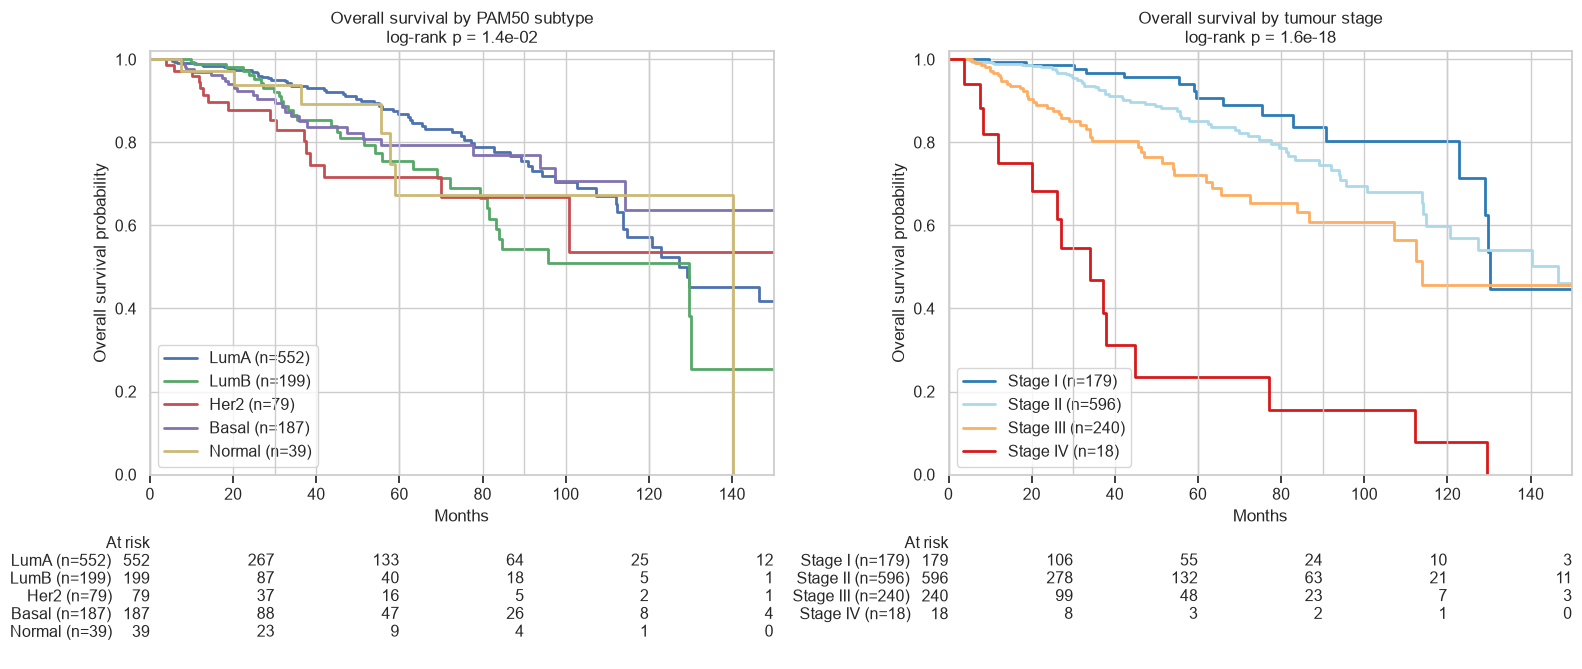

Log-rank subtype p = 1.38e-02 | stage p = 1.57e-18
              test_statistic       p  -log2(p)
Basal Her2            3.2763  0.0703    3.8306
      LumA            0.4625  0.4965    1.0102
      LumB            1.5723  0.2099    2.2524
      Normal          0.1515  0.6971    0.5206
Her2  LumA            9.2831  0.0023    8.7562
      LumB            0.4570  0.4990    1.0028
      Normal          0.5218  0.4701    1.0890
LumA  LumB            6.8012  0.0091    6.7784
      Normal          1.1523  0.2831    1.8208
LumB  Normal          0.2936  0.5879    0.7664
subtype   n  deaths  5-yr OS
   LumA 552      66    0.868
   LumB 199      33    0.756
   Her2  79      17    0.717
  Basal 187      27    0.793
 Normal  39       7    0.674


In [2]:
def km_plot(ax, df, group, levels, colors, title):
    fitters = []
    for lev in levels:
        d = df[df[group] == lev]
        kmf = KaplanMeierFitter(label=f"{lev} (n={len(d)})").fit(d["OS_months"], d["OS_event"])
        kmf.plot_survival_function(ax=ax, ci_show=False, color=colors[lev], lw=2)
        fitters.append(kmf)
    lr = multivariate_logrank_test(df["OS_months"], df[group], df["OS_event"])
    ax.set(title=f"{title}\nlog-rank p = {lr.p_value:.1e}", xlabel="Months", ylabel="Overall survival probability",
           xlim=(0, 150), ylim=(0, 1.02))
    add_at_risk_counts(*fitters, ax=ax, rows_to_show=["At risk"], xticks=[0, 30, 60, 90, 120, 150])
    return lr

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
lr_sub = km_plot(axes[0], surv, "subtype", SUB_ORDER, PALETTE, "Overall survival by PAM50 subtype")
lr_st  = km_plot(axes[1], surv.dropna(subset=["stage_group"]), "stage_group", STAGES,
                 dict(zip(STAGES, ["#2c7bb6", "#abd9e9", "#fdae61", "#d7191c"])), "Overall survival by tumour stage")
plt.tight_layout(); plt.savefig(FIG / "09_kaplan_meier.png", dpi=200, bbox_inches="tight"); plt.show()

pw = pairwise_logrank_test(surv["OS_months"], surv["subtype"], surv["OS_event"]).summary
pw.to_csv(TAB / "09_pairwise_logrank_subtype.csv")
print(f"Log-rank subtype p = {lr_sub.p_value:.2e} | stage p = {lr_st.p_value:.2e}")
print(pw.round(4))

rows = []
for s in SUB_ORDER:
    d = surv[surv["subtype"] == s]
    kmf = KaplanMeierFitter().fit(d["OS_months"], d["OS_event"])
    rows.append({"subtype": s, "n": len(d), "deaths": int(d["OS_event"].sum()),
                 "5-yr OS": round(float(kmf.survival_function_at_times(60).iloc[0]), 3)})
print(pd.DataFrame(rows).to_string(index=False))

In [5]:
# 5-year overall survival per subtype
rows = []
for s in SUB_ORDER:
    d = surv[surv["subtype"] == s]
    kmf = KaplanMeierFitter().fit(d["OS_months"], d["OS_event"])
    rows.append({"Subtype": s, "n": len(d), "Deaths": int(d["OS_event"].sum()),
                 "5-year OS (%)": round(100 * float(kmf.survival_function_at_times(60).iloc[0]), 1),
                 "Median follow-up (months)": round(d["OS_months"].median(), 1)})
km5 = pd.DataFrame(rows).sort_values("5-year OS (%)", ascending=False)
km5.to_csv(TAB / "09_5yr_survival.csv", index=False)
display(km5)

,Subtype,n,Deaths,5-year OS (%),Median follow-up (months)
0,LumA,552,66,86.8,28.9
3,Basal,187,27,79.3,27.0
1,LumB,199,33,75.6,24.8
2,Her2,79,17,71.7,22.3
4,Normal,39,7,67.4,36.3



Model 1: subtype + stage + age  (C-index = 0.771)
                exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                 
subtype_LumB        1.394                0.892                2.178  0.144
subtype_Her2        2.708                1.562                4.694  0.000
subtype_Basal       1.738                1.084                2.787  0.022
subtype_Normal      1.836                0.833                4.043  0.132
stage_II            1.634                0.938                2.848  0.083
stage_III           3.696                2.064                6.617  0.000
stage_IV           11.218                5.357               23.489  0.000
age_10y             1.475                1.291                1.686  0.000

Model 2: proliferation + stage + age  (C-index = 0.765)
              exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                            

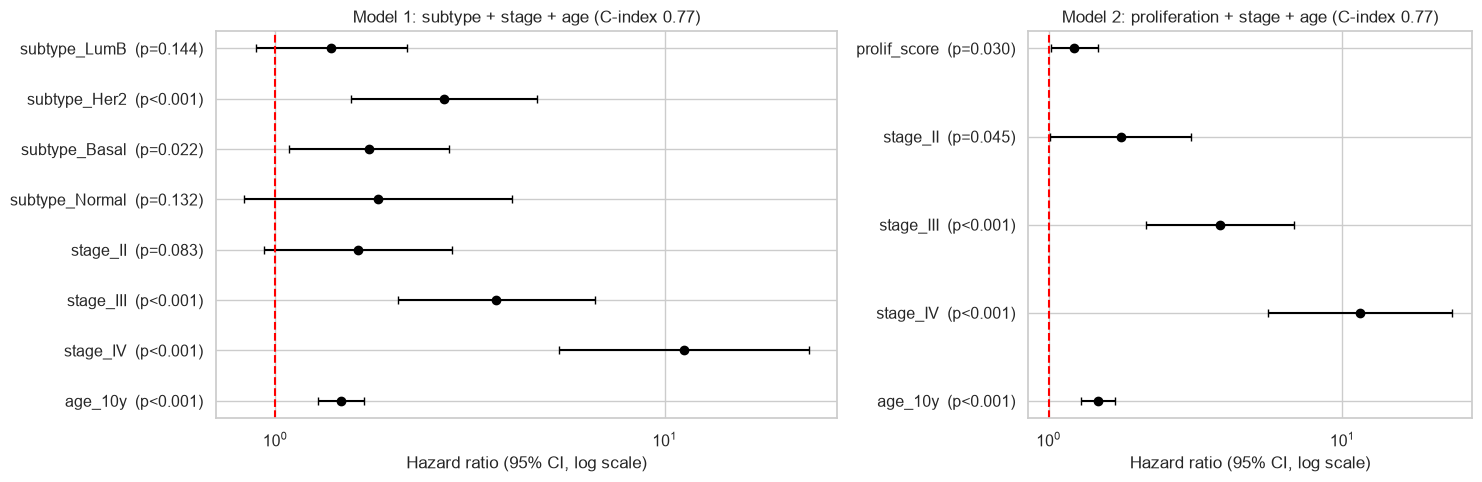


PH assumption test (p < 0.05 = violated):
                     p
age_10y         0.108
stage_II        0.674
stage_III       0.015
stage_IV        0.013
subtype_Basal   0.001
subtype_Her2    0.111
subtype_LumB    0.419
subtype_Normal  0.690


In [3]:
cox_df = surv.dropna(subset=["stage_group", "age"]).copy()
cox_df["age_10y"] = cox_df["age"] / 10
for s in SUB_ORDER[1:]:
    cox_df[f"subtype_{s}"] = (cox_df["subtype"] == s).astype(int)                    # reference = LumA
for st in STAGES[1:]:
    cox_df[f"stage_{st.split()[1]}"] = (cox_df["stage_group"] == st).astype(int)     # reference = Stage I
covars = [f"subtype_{s}" for s in SUB_ORDER[1:]] + [f"stage_{st.split()[1]}" for st in STAGES[1:]] + ["age_10y"]

cph1 = CoxPHFitter().fit(cox_df[["OS_months", "OS_event"] + covars], "OS_months", "OS_event")
cph2 = CoxPHFitter().fit(cox_df[["OS_months", "OS_event", "prolif_score"] + covars[4:]], "OS_months", "OS_event")
for name, m in [("Model 1: subtype + stage + age", cph1), ("Model 2: proliferation + stage + age", cph2)]:
    print(f"\n{name}  (C-index = {m.concordance_index_:.3f})")
    print(m.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3))
cph1.summary.to_csv(TAB / "09_cox_subtype.csv"); cph2.summary.to_csv(TAB / "09_cox_prolif.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})
for ax, m, title in [(axes[0], cph1, f"Model 1: subtype + stage + age (C-index {cph1.concordance_index_:.2f})"),
                     (axes[1], cph2, f"Model 2: proliferation + stage + age (C-index {cph2.concordance_index_:.2f})")]:
    sm = m.summary.iloc[::-1]
    yy = np.arange(len(sm))
    ax.errorbar(sm["exp(coef)"], yy, xerr=[sm["exp(coef)"] - sm["exp(coef) lower 95%"],
                                           sm["exp(coef) upper 95%"] - sm["exp(coef)"]], fmt="o", color="black", capsize=3)
    ax.axvline(1, color="red", ls="--")
    ax.set_yticks(yy); ax.set_yticklabels([f"{i}  (p{'<0.001' if p < 0.001 else f'={p:.3f}'})" for i, p in zip(sm.index, sm["p"])])
    ax.set(xscale="log", xlabel="Hazard ratio (95% CI, log scale)", title=title)
plt.tight_layout(); plt.savefig(FIG / "09_cox_forest.png", dpi=200); plt.show()

# check the proportional-hazards assumption (Schoenfeld residuals)
ph = proportional_hazard_test(cph1, cox_df[["OS_months", "OS_event"] + covars], time_transform="rank")
print("\nPH assumption test (p < 0.05 = violated):\n", ph.summary[["p"]].round(3))

                         model               term    coef  CI_low  CI_high      p     R2
          prolif ~ age + stage  stage[T.Stage II]  0.3440  0.1988   0.4891 0.0000 0.0396
          prolif ~ age + stage stage[T.Stage III]  0.1831  0.0152   0.3509 0.0326 0.0396
          prolif ~ age + stage  stage[T.Stage IV]  0.2338 -0.1801   0.6478 0.2679 0.0396
          prolif ~ age + stage                age -0.0087 -0.0127  -0.0047 0.0000 0.0396
prolif ~ age + stage + subtype  stage[T.Stage II]  0.1280  0.0276   0.2285 0.0125 0.5496
prolif ~ age + stage + subtype stage[T.Stage III]  0.0723 -0.0435   0.1882 0.2207 0.5496
prolif ~ age + stage + subtype  stage[T.Stage IV]  0.0071 -0.2776   0.2919 0.9609 0.5496
prolif ~ age + stage + subtype   subtype[T.Basal]  1.5103  1.4091   1.6114 0.0000 0.5496
prolif ~ age + stage + subtype    subtype[T.Her2]  1.0047  0.8630   1.1464 0.0000 0.5496
prolif ~ age + stage + subtype    subtype[T.LumB]  1.1009  1.0041   1.1976 0.0000 0.5496
prolif ~ age + stage 

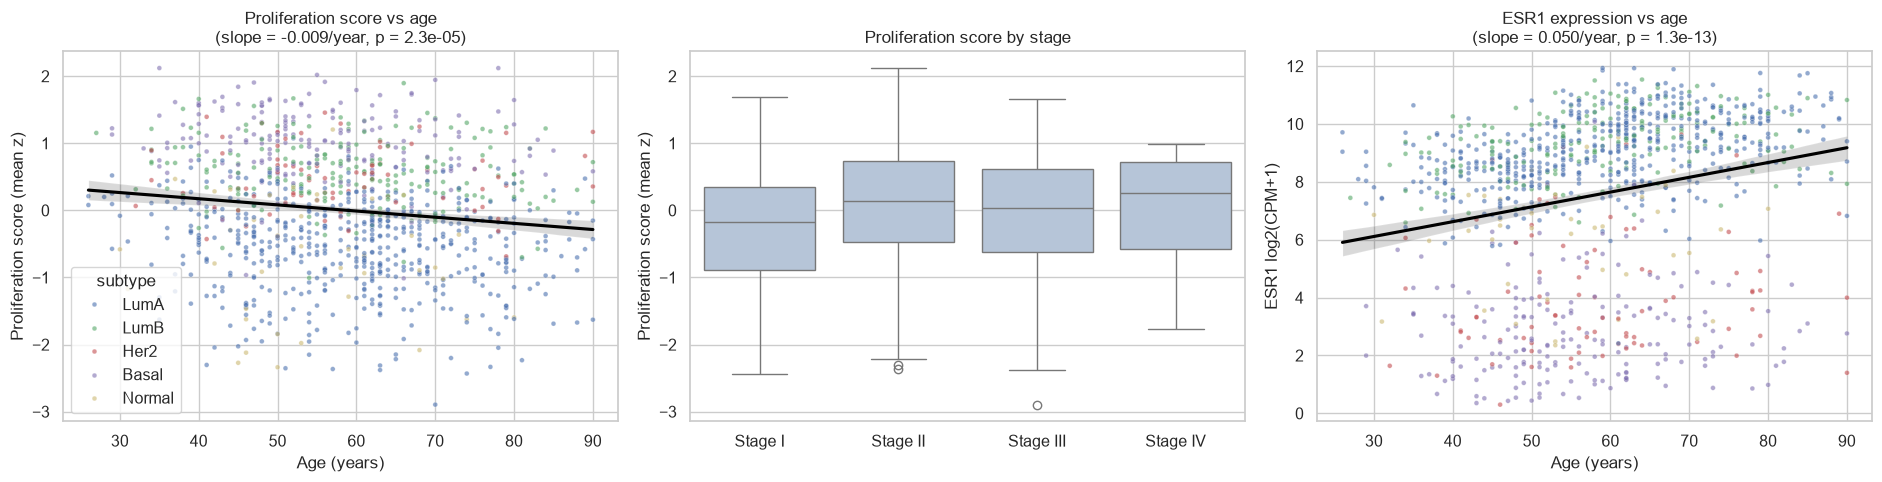

In [4]:
reg = meta.dropna(subset=["age", "stage_group"]).copy()
reg["ESR1"] = logcpm.loc["ESR1", reg["sample_id"]].values
ST, SU = "C(stage_group, Treatment('Stage I'))", "C(subtype, Treatment('LumA'))"
ols_models = {
    "prolif ~ age + stage":           smf.ols(f"prolif_score ~ age + {ST}", data=reg).fit(),
    "prolif ~ age + stage + subtype": smf.ols(f"prolif_score ~ age + {ST} + {SU}", data=reg).fit(),
    "ESR1 ~ age + stage":             smf.ols(f"ESR1 ~ age + {ST}", data=reg).fit(),
    "ESR1 ~ age + stage + subtype":   smf.ols(f"ESR1 ~ age + {ST} + {SU}", data=reg).fit(),
}
rows = []
for name, m in ols_models.items():
    ci = m.conf_int()
    for term in m.params.index.drop("Intercept"):
        rows.append({"model": name, "term": term.replace(ST, "stage").replace(SU, "subtype"),
                     "coef": m.params[term], "CI_low": ci.loc[term, 0], "CI_high": ci.loc[term, 1],
                     "p": m.pvalues[term], "R2": m.rsquared})
ols_tab = pd.DataFrame(rows); ols_tab.to_csv(TAB / "09_linear_regression.csv", index=False)
print(ols_tab.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.scatterplot(data=reg, x="age", y="prolif_score", hue="subtype", hue_order=SUB_ORDER, palette=PALETTE, s=12, alpha=0.6, ax=axes[0])
sns.regplot(data=reg, x="age", y="prolif_score", scatter=False, color="black", ax=axes[0])
m = ols_models["prolif ~ age + stage"]
axes[0].set(title=f"Proliferation score vs age\n(slope = {m.params['age']:.3f}/year, p = {m.pvalues['age']:.1e})",
            xlabel="Age (years)", ylabel="Proliferation score (mean z)")
sns.boxplot(data=reg, x="stage_group", y="prolif_score", order=STAGES, ax=axes[1], color="lightsteelblue")
axes[1].set(title="Proliferation score by stage", xlabel="", ylabel="Proliferation score (mean z)")
sns.scatterplot(data=reg, x="age", y="ESR1", hue="subtype", hue_order=SUB_ORDER, palette=PALETTE, s=12, alpha=0.6, ax=axes[2], legend=False)
sns.regplot(data=reg, x="age", y="ESR1", scatter=False, color="black", ax=axes[2])
m = ols_models["ESR1 ~ age + stage"]
axes[2].set(title=f"ESR1 expression vs age\n(slope = {m.params['age']:.3f}/year, p = {m.pvalues['age']:.1e})",
            xlabel="Age (years)", ylabel="ESR1 log2(CPM+1)")
plt.tight_layout(); plt.savefig(FIG / "09_regression.png", dpi=200); plt.show()